<a href="https://colab.research.google.com/github/LNBMS/dev/blob/main/datawrangling_ex.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#https://www.kaggle.com/datasets/dskagglemt/student-performance-data-set
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dskagglemt/student-performance-data-set")

print("Path to dataset files:", path)

100%|██████████| 21.6k/21.6k [00:00<00:00, 23.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/dskagglemt/student-performance-data-set/versions/1


In [5]:
import os

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

/root/.cache/kagglehub/datasets/dskagglemt/student-performance-data-set/versions/1/student-por.csv
/root/.cache/kagglehub/datasets/dskagglemt/student-performance-data-set/versions/1/student-mat.csv
/root/.cache/kagglehub/datasets/dskagglemt/student-performance-data-set/versions/1/student.txt
/root/.cache/kagglehub/datasets/dskagglemt/student-performance-data-set/versions/1/student-merge.R


In [6]:
import pandas as pd
import os

file_path = os.path.join(path, "student-mat.csv")

df = pd.read_csv(file_path, sep=";")

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


inspect the raw data

In [7]:
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Rows and columns: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absence

**Standardize column names**
Column names such as Pstatus, Medu and G3 are not immediately descriptive to beginners.

In [8]:
df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'pstatus', 'medu', 'fedu', 'mjob', 'fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'dalc', 'walc', 'health', 'absences', 'g1', 'g2', 'g3']


**Clean categorical values**

Remove accidental spaces and standardize the capitalization of text columns.
for example in dataset GP becomes gp, and F becomes f

In [9]:
text_columns = df.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df[col] = df[col].str.strip().str.lower()

print(df[text_columns].head())

  school sex address famsize pstatus     mjob      fjob  reason guardian  \
0     gp   f       u     gt3       a  at_home   teacher  course   mother   
1     gp   f       u     gt3       t  at_home     other  course   father   
2     gp   f       u     le3       t  at_home     other   other   mother   
3     gp   f       u     gt3       t   health  services    home   mother   
4     gp   f       u     gt3       t    other     other    home   father   

  schoolsup famsup paid activities nursery higher internet romantic  
0       yes     no   no         no     yes    yes       no       no  
1        no    yes   no         no      no    yes      yes       no  
2       yes     no  yes         no     yes    yes      yes       no  
3        no    yes  yes        yes     yes    yes      yes      yes  
4        no    yes  yes         no     yes    yes       no       no  


**Find missing values**

In [10]:
missing = df.isnull().sum()

print(missing[missing > 0])

Series([], dtype: int64)


#in this dataset no missing values

**Find duplicate records**

In [11]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicate rows: 0


**Check incorrect values**
For this dataset, grades should be within the range 0–20.


In [12]:
for col in ["g1", "g2", "g3"]:
    invalid = df[~df[col].between(0, 20)]
    print(col, "invalid rows:", len(invalid))

g1 invalid rows: 0
g2 invalid rows: 0
g3 invalid rows: 0


**Create a new column**
Create a final-grade category based on g3

High: final grade of 15 or above



Pass: final grade from 10 to below 15



Below 10: final grade below 10

In [13]:
df["performance"] = np.select(
    [
        df["g3"] >= 15,
        df["g3"] >= 10
    ],
    [
        "High",
        "Pass"
    ],
    default="Below 10"
)

print(df[["g1", "g2", "g3", "performance"]].head(10))

   g1  g2  g3 performance
0   5   6   6    Below 10
1   5   5   6    Below 10
2   7   8  10        Pass
3  15  14  15        High
4   6  10  10        Pass
5  15  15  15        High
6  12  12  11        Pass
7   6   5   6    Below 10
8  16  18  19        High
9  14  15  15        High


**Filter students**
Find students whose final grade is at least 15.

In [14]:
high_performers = df[df["g3"] >= 15]

print(high_performers[["age", "studytime", "absences", "g3"]].head(10))

print("Number of high performers:", len(high_performers))

    age  studytime  absences  g3
3    15          3         2  15
5    16          2        10  15
8    15          2         0  19
9    15          2         0  15
14   15          3         0  16
20   15          2         0  15
21   15          1         0  15
22   16          2         2  16
27   15          1         4  15
31   15          2         0  17
Number of high performers: 73


**sort records**

In [15]:
df_sorted = df.sort_values(
    by="g3",
    ascending=False
)

print(df_sorted[["age", "studytime", "g3"]].head(10))

     age  studytime  g3
47    16          4  20
286   18          3  19
374   18          3  19
110   15          1  19
8     15          2  19
113   15          1  19
91    15          1  18
42    15          2  18
36    15          3  18
104   15          2  18


**Group and summarize**
Calculate the average final grade for each study-time category.

In [16]:
study_summary = (
    df.groupby("studytime")["g3"]
      .agg(["count", "mean", "min", "max"])
      .round(2)
)

print(study_summary)

           count   mean  min  max
studytime                        
1            105  10.05    0   19
2            198  10.17    0   19
3             65  11.40    0   19
4             27  11.26    0   20


**Save the cleaned dataset**

In [17]:
df.to_csv(
    "/content/student_performance_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

Cleaned dataset saved.


In [18]:
cleaned_df = pd.read_csv(
    "/content/student_performance_cleaned.csv"
)

print(cleaned_df.shape)
print(cleaned_df.head())

(395, 34)
  school sex  age address famsize pstatus  medu  fedu     mjob      fjob  ...  \
0     gp   f   18       u     gt3       a     4     4  at_home   teacher  ...   
1     gp   f   17       u     gt3       t     1     1  at_home     other  ...   
2     gp   f   15       u     le3       t     1     1  at_home     other  ...   
3     gp   f   15       u     gt3       t     4     2   health  services  ...   
4     gp   f   16       u     gt3       t     3     3    other     other  ...   

  freetime goout  dalc  walc  health absences  g1  g2  g3 performance  
0        3     4     1     1       3        6   5   6   6    Below 10  
1        3     3     1     1       3        4   5   5   6    Below 10  
2        3     2     2     3       3       10   7   8  10        Pass  
3        2     2     1     1       5        2  15  14  15        High  
4        3     2     1     2       5        4   6  10  10        Pass  

[5 rows x 34 columns]


**Explore  results**

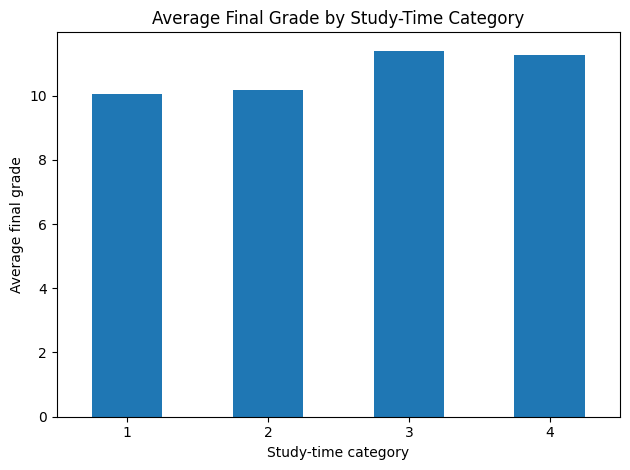

In [19]:
import matplotlib.pyplot as plt

study_summary["mean"].plot(
    kind="bar",
    title="Average Final Grade by Study-Time Category",
    xlabel="Study-time category",
    ylabel="Average final grade",
    rot=0
)

plt.tight_layout()
plt.show()